# Laboratoire Calorvia : pistes pour les langues, les fichiers Excel et les images

Ce notebook accompagne l'énoncé du laboratoire. Il ne donne pas de solution complète : il montre trois problèmes du corpus Calorvia sur des exemples réels, puis propose des pistes pour les traiter.

| Partie | Problème | Pistes |
|---|---|---|
| 1. Les langues | 44 documents en néerlandais et 7 en anglais, des questions en français | Détecter la langue, embedder multilingue, traduire la question, répondre en français |
| 2. Les fichiers Excel | Ce que Docling en fait est difficile à chercher | Lire les onglets avec openpyxl, une phrase par ligne, calculer avec polars |
| 3. Les images et les scans | 54 images et 9 PDF scannés sans texte | Transcrire avec un VLM servi par llama-server, garder le chemin de l'image, **bonus** : afficher l'image dans le chat |

Les cellules qui appellent un modèle (LLM, embedder, VLM) n'ont pas été exécutées ici : elles n'ont donc pas de résultat. Lancez-les sur la machine du cours, une fois les services démarrés. Toutes les autres cellules ont été exécutées sur le corpus.

Le notebook suppose l'arborescence du dépôt : il est rangé dans `notebooks/`, et le corpus dans `data/calorvia/`.

In [1]:
from pathlib import Path

import polars as pl
from openai import OpenAI

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CORPUS = ROOT / "data" / "calorvia"

# In the application, these values come from config.py (.env)
LLM_URL, LLM_MODEL = "http://localhost:8000/v1", "llm"
EMBEDDINGS_URL, EMBEDDING_MODEL = "http://localhost:8001/v1", "bge-m3"
VLM_URL, VLM_MODEL = "http://localhost:8005/v1", "vlm"

pl.Config.set_tbl_rows(30)
pl.Config.set_fmt_str_lengths(90)
pl.Config.set_tbl_width_chars(160)

files = pl.DataFrame([
    {"path": str(p.relative_to(CORPUS)), "folder": p.relative_to(CORPUS).parts[0],
     "format": p.suffix.lower().lstrip("."), "size_kb": round(p.stat().st_size / 1024, 1)}
    for p in sorted(CORPUS.rglob("*")) if p.is_file()
])
print(len(files), "fichiers")
files.group_by("format").len().sort("len", descending=True)

393 fichiers


format,len
str,u32
"""docx""",156
"""pdf""",85
"""xlsx""",55
"""jpg""",31
"""html""",31
"""png""",23
"""pptx""",9
"""csv""",2
"""md""",1


## 1. Les langues

Le site de Gand écrit en néerlandais (rapports de production, comité de sécurité, incident, procédures). Les contrats fournisseurs et deux communiqués sont en anglais. Les questions, elles, sont toujours en français.

### 1.1 Détecter la langue de chaque document

Pour connaître la langue, inutile de lancer la conversion complète : un texte brut suffit. Pour un PDF, on lit sa couche texte avec PyMuPDF ; pour les autres formats, Docling est rapide. On reprend la fonction `detect_language()` du chapitre 05.

In [5]:
import pymupdf
from docling.document_converter import DocumentConverter
from py3langid.langid import MODEL_FILE, LanguageIdentifier

converter = DocumentConverter()
identifier = LanguageIdentifier.from_model_file(MODEL_FILE, norm_probs=True)
identifier.set_languages(["fr", "nl", "en", "de"])


def quick_text(path):
    """Raw text of a document, enough to detect its language. PDF: text layer only (empty for a scan)."""
    if path.suffix.lower() == ".pdf":
        with pymupdf.open(path) as pdf:
            return " ".join(page.get_text() for page in pdf)
    return converter.convert(path).document.export_to_text()


def detect_language(text, default="fr", min_probability=0.9):
    """Language of a text; `default` when the text is too short or the detection is not reliable."""
    if len(text.split()) < 5:
        return default
    language, probability = identifier.classify(text)
    return language if probability >= min_probability else default

In [8]:
TEXT_FORMATS = {"docx", "pdf", "html", "pptx", "md", "xlsx", "csv"}

rows = []
for path in sorted(CORPUS.rglob("*")):
    if path.is_file() and path.suffix.lower().lstrip(".") in TEXT_FORMATS:
        text = quick_text(path)
        rows.append({"path": str(path.relative_to(CORPUS)), "folder": path.relative_to(CORPUS).parts[0],
                     "words": len(text.split()),
                     "language": detect_language(text) if text.strip() else None})
languages = pl.DataFrame(rows)
languages.group_by("language").len().sort("len", descending=True)

language,len
str,u32
"""fr""",284
"""nl""",38
null,10
"""en""",7


Les documents sans langue (`null`) n'ont pas de texte : ce sont les 9 PDF scannés, à traiter avec la partie 3, et un document Word vide. Aux 38 documents néerlandais s'ajoutent 6 images en néerlandais (plaques signalétiques, affiche et plan de l'entrepôt de Gand), que l'on ne peut lire qu'avec la partie 3. Où sont les documents qui ne sont pas en français ?

In [7]:
(languages.filter(pl.col("language").is_in(["nl", "en"]))
    .with_columns(pl.col("path").str.replace(r"/[^/]+$", "").alias("dossier"))
    .group_by("dossier", "language").len().sort("len", descending=True))

dossier,language,len
str,str,u32
"""03_Production/Gent/Maandrapporten""","""nl""",9
"""03_Production/Gent/Veiligheid/Comite PBW""","""nl""",9
"""05_Commercial/Fiches_produits""","""nl""",6
"""02_RH/Recrutement/Offres""","""nl""",4
"""05_Commercial/Fiches_produits""","""en""",3
"""03_Production/Gent/Veiligheid""","""nl""",2
"""06_Achats/Fournisseurs""","""en""",2
"""09_Communication/Communiques_presse""","""en""",2
"""03_Production/Procedures""","""nl""",2


Deux remarques :

- la détection se fait au niveau du document. Un document peut mélanger les langues (un PV français qui cite un rapport néerlandais) : pour être précis, détectez la langue **de chaque chunk** et mettez-la dans le payload, comme au chapitre 05 ;
- la langue détectée sert à choisir le stemmer de la recherche lexicale (`bm25(text, language)` du chapitre 05) et à analyser les métriques par langue. Elle ne doit **pas** servir de filtre : la réponse à une question en français peut se trouver dans un document néerlandais.

### 1.2 Le problème : la recherche lexicale ne traverse pas les langues

Prenons une question du jeu d'évaluation et deux passages qui y répondent, l'un en français, l'autre en néerlandais.

In [9]:
import re
import unicodedata

question = ("Quelle est la vitesse maximale autorisée pour les chariots élévateurs dans les allées "
            "de stockage de l'entrepôt de Gand ?")
passage_fr = ("Gand : la vitesse maximale des chariots est abaissée de 8 à 6 km/h dans les allées de stockage ; "
              "elle est fixée à 10 km/h sur les voies de circulation principales.")
passage_nl = "Vanaf vandaag: maximum 6 km/u in de gangen en 10 km/u op de hoofdverkeersweg."

STOPWORDS = {"quelle", "est", "les", "des", "dans", "pour", "la", "le", "de", "du", "et", "en", "op", "van", "in"}


def words(text):
    """Lower-case words without accents, without stopwords and very short words."""
    text = unicodedata.normalize("NFKD", text.lower())
    text = "".join(c for c in text if not unicodedata.combining(c))
    return {w for w in re.findall(r"[a-z0-9]+", text) if len(w) > 2 and w not in STOPWORDS}


print("Mots communs avec le passage français   :", sorted(words(question) & words(passage_fr)))
print("Mots communs avec le passage néerlandais :", sorted(words(question) & words(passage_nl)))

Mots communs avec le passage français   : ['allees', 'chariots', 'gand', 'maximale', 'stockage', 'vitesse']
Mots communs avec le passage néerlandais : []


Le passage néerlandais ne partage aucun mot avec la question : la recherche BM25 ne le trouvera jamais. La recherche dense, elle, compare des sens et non des mots : avec un embedder **multilingue** (bge-m3, Qwen3-Embedding et Harrier le sont), une question en français peut retrouver un passage en néerlandais. Vérifiez-le :

In [14]:
import numpy as np

embedding_client = OpenAI(base_url=EMBEDDINGS_URL, api_key="no-key")


def embed(texts):
    response = embedding_client.embeddings.create(model=EMBEDDING_MODEL, input=texts)
    vectors = np.array([item.embedding for item in response.data])
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


unrelated = "La campagne de sensibilisation à l'hameçonnage a formé 186 personnes."
q, fr, nl, other = embed([question, passage_fr, passage_nl, unrelated])   # add the query instruction if needed
print(f"question / passage français    : {q @ fr:.3f}")
print(f"question / passage néerlandais : {q @ nl:.3f}")
print(f"question / passage hors sujet  : {q @ other:.3f}")

question / passage français    : 0.743
question / passage néerlandais : 0.508
question / passage hors sujet  : 0.276


Si le passage néerlandais obtient un score nettement plus haut que le passage hors sujet, la recherche dense fait le pont entre les langues. Dans la recherche hybride, la partie lexicale ne l'aide pas : le passage néerlandais n'arrive que par la recherche dense.

### 1.3 Piste A : traduire la question

On demande au LLM de traduire la question en néerlandais et en anglais, puis on cherche avec les trois versions, chacune dans les deux recherches (dense et lexicale, avec le bon stemmer). Les six listes sont fusionnées par RRF, comme la recherche hybride du cours.

In [16]:
import json

llm = OpenAI(base_url=LLM_URL, api_key="no-key")

TRANSLATION_PROMPT = """Traduis la question en néerlandais et en anglais, sans y répondre.
Garde tels quels les noms propres, les codes, les nombres et les unités.
Réponds uniquement avec un objet JSON de la forme {"nl": "...", "en": "..."}."""


def translate_question(question):
    """{'fr': question, 'nl': ..., 'en': ...}; only the French question if the LLM answer is not valid JSON."""
    response = llm.chat.completions.create(
        model=LLM_MODEL, temperature=0,
        messages=[{"role": "system", "content": TRANSLATION_PROMPT}, {"role": "user", "content": question}],
        response_format={"type": "json_object"},
    )
    try:
        translations = json.loads(response.choices[0].message.content)
        return {"fr": question, **{k: v for k, v in translations.items() if k in ("nl", "en") and v}}
    except json.JSONDecodeError:
        return {"fr": question}


translations = translate_question(question)
translations

{'fr': "Quelle est la vitesse maximale autorisée pour les chariots élévateurs dans les allées de stockage de l'entrepôt de Gand ?",
 'nl': 'Wat is de maximale toegestane snelheid voor reachtrucks in de opslaggangen van het magazijn van Gand?',
 'en': 'What is the maximum permitted speed for forklifts in the storage aisles of the Gand warehouse?'}

La recherche, avec les fonctions de votre application : `embed_query()` (l'embedding de la question, avec l'instruction si l'embedder en demande une), `bm25()` du chapitre 05 et la collection de l'exercice 3 :

```python
from qdrant_client import models

prefetch = []
for language, text in translations.items():
    prefetch.append(models.Prefetch(query=embed_query(text), using="dense", limit=30))
    prefetch.append(models.Prefetch(query=bm25(text, language=language), using="sparse", limit=30))

points = qdrant.query_points(collection, prefetch=prefetch,
                             query=models.RrfQuery(rrf=models.Rrf(k=60)), limit=30).points
# then the reranker, as usual
```

Ce que coûte cette piste : un appel au LLM par question (de l'ordre de la seconde) et quatre recherches de plus. À mesurer sur les questions `multilingual`, mais aussi sur toutes les autres : les traductions ajoutent des candidats, parfois du bruit.

### 1.4 Autres pistes

| Piste | Idée | Coût |
|---|---|---|
| Traduire à l'indexation | Pour chaque chunk néerlandais ou anglais, indexer aussi sa traduction française (un second point, ou un second vecteur) | Un appel au LLM par chunk, une seule fois |
| Reranker multilingue | Le reranker compare question et passage : bge-reranker-v2-m3 et Qwen3-Reranker sont multilingues | Rien de plus, mais à vérifier sur les questions `multilingual` |
| Répondre en français | Le prompt système demande de toujours répondre en français, même si l'extrait est en néerlandais, en citant si besoin le passage original | Une ligne de prompt |
| Mesurer par langue | Ajouter la langue des documents de preuve dans l'analyse des résultats | Une jointure en SQL |

## 2. Les fichiers Excel

Le corpus contient 55 classeurs : budget en trois versions, reporting mensuel, rapports de production, tarifs, suivi du rappel produit, enquête, plan de formation… La plupart des questions `excel_lookup` et `excel_reasoning` n'ont leur réponse que là.

### 2.1 Ce que Docling en fait

In [17]:
path = CORPUS / "01_Finance/Reporting_mensuel/Reporting 2026-03.xlsx"
markdown = converter.convert(path).document.export_to_markdown()
print("\n".join(markdown.splitlines()[:22]))

| Reporting mensuel · mars 2026        | Reporting mensuel · mars 2026        | Reporting mensuel · mars 2026        | Reporting mensuel · mars 2026        | Reporting mensuel · mars 2026        |
|--------------------------------------|--------------------------------------|--------------------------------------|--------------------------------------|--------------------------------------|
| Montants en k€ · contrôle de gestion | Montants en k€ · contrôle de gestion | Montants en k€ · contrôle de gestion | Montants en k€ · contrôle de gestion | Montants en k€ · contrôle de gestion |
| Indicateur                           | Mois                                 | Cumul annuel                         | Budget cumul                         | Écart au budget                      |
| Chiffre d'affaires                   | 13600                                | 41400                                | 41684                                | -0.7%                                |
| Marge brute  

Plusieurs problèmes apparaissent :

- **le titre fusionné est recopié dans chaque colonne** : la cellule fusionnée « Reporting mensuel · mars 2026 » devient une ligne de tableau répétée cinq fois ;
- **les nombres sont bruts** : l'écart au budget s'affiche `-0.00681316572305923` au lieu de `-0,7 %`. Excel affiche la valeur selon le format de la cellule ; Docling lit la valeur stockée ;
- **le nom de l'onglet disparaît** : « Synthèse », « Ventes par région »… ne figurent nulle part dans le texte ;
- **l'unité est perdue** : les montants sont en k€, mais seule la ligne de sous-titre le dit ;
- **une fois découpé**, un grand tableau donne des chunks de lignes sans leur en-tête, qui ne disent plus de quel mois ni de quel onglet il s'agit.

### 2.2 Lire le classeur soi-même avec openpyxl

In [18]:
from openpyxl import load_workbook

workbook = load_workbook(path, data_only=True)    # data_only: the values computed by Excel, not the formulas
for ws in workbook.worksheets:
    merged = [str(r) for r in ws.merged_cells.ranges]
    print(f"{ws.title:20} {ws.dimensions:8} état={ws.sheet_state:8} fusions={merged}")

cell = workbook["Synthèse"]["E4"]
print("\nE4 :", cell.value, "| format :", cell.number_format)

Synthèse             A1:E8    état=visible  fusions=['A2:E2', 'A1:E1']
Ventes par gamme     A1:C9    état=visible  fusions=['A1:C1']
Ventes par région    A1:C9    état=visible  fusions=['A1:C1']
Effectifs            A1:B8    état=visible  fusions=['A1:B1']
Commentaires         A1:A3    état=visible  fusions=[]

E4 : -0.00681316572305923 | format : 0.0%


`data_only=True` renvoie la valeur que le tableur a calculée et enregistrée avec le fichier. Un classeur produit par un script (et jamais ouvert dans Excel ou LibreOffice) peut ne contenir que les formules : la valeur lue est alors `None`. Les classeurs du corpus ont tous leurs valeurs, mais vérifiez-le pour vos propres fichiers :

In [19]:
def uncached_formulas(path):
    """Number of formula cells without a cached value (they would be read as empty)."""
    formulas = load_workbook(path)
    values = load_workbook(path, data_only=True)
    count = 0
    for ws in formulas.worksheets:
        for row in ws.iter_rows():
            for cell in row:
                if cell.data_type == "f" and values[ws.title][cell.coordinate].value is None:
                    count += 1
    return count


sum(uncached_formulas(p) for p in CORPUS.rglob("*.xlsx"))

0

### 2.3 Retrouver les tableaux d'un onglet

Un onglet contient souvent un titre, un sous-titre, un tableau, puis des notes. On le découpe en blocs de lignes non vides ; dans un bloc, une ligne d'une seule cellule est un titre ou une note, la première ligne de plusieurs cellules est l'en-tête du tableau.

In [20]:
def sheet_tables(ws):
    """Tables of a sheet: [{'title', 'header', 'rows', 'notes'}]. Rows are lists of openpyxl cells."""
    tables, title, current = [], None, None
    for row in ws.iter_rows():
        cells = [c for c in row if c.value is not None]
        if not cells:                                   # an empty row closes the current table
            current = None
            continue
        if len(cells) == 1 and current is None:         # a single cell outside a table: title or subtitle
            title = cells[0].value if title is None else f"{title} · {cells[0].value}"
            continue
        if len(cells) == 1:                             # a single cell after a table: a note
            current["notes"].append(str(cells[0].value))
            continue
        if current is None:                             # first row with several cells: the header
            current = {"title": title, "header": [c.value for c in row], "rows": [], "notes": []}
            tables.append(current)
            title = None
        else:
            current["rows"].append(list(row))
    return tables


for ws in workbook.worksheets:
    for table in sheet_tables(ws):
        print(f"[{ws.title}] titre={table['title']!r}")
        print(f"   en-tête={table['header']}, {len(table['rows'])} lignes")

[Synthèse] titre='Reporting mensuel · mars 2026 · Montants en k€ · contrôle de gestion'
   en-tête=['Indicateur', 'Mois', 'Cumul annuel', 'Budget cumul', 'Écart au budget'], 5 lignes
[Ventes par gamme] titre="Chiffre d'affaires par gamme (k€)"
   en-tête=['Gamme', 'CA du mois', 'Part'], 6 lignes
[Ventes par région] titre="Chiffre d'affaires par région (k€)"
   en-tête=['Région', 'CA du mois', 'Part'], 6 lignes
[Effectifs] titre='Effectif par site en fin de mois (ETP)'
   en-tête=['Site', 'ETP'], 5 lignes


### 2.4 Afficher les valeurs comme Excel

Le format de la cellule dit comment afficher la valeur. On traite les cas utiles : les pourcentages, les nombres entiers stockés en décimal, les dates.

> **Attention au jeu d'évaluation.** Les extraits de preuve des fichiers Excel ont été écrits d'après le rendu de Docling : `4568`, `41.5`, sans séparateur de milliers. La fonction ci-dessous garde ce rendu pour les nombres et ne change que les pourcentages et les dates. Si vous formatez autrement (`4 568`, `41,5`), normalisez les nombres dans `judge_chunk()` : supprimez les espaces entre deux chiffres et remplacez la virgule décimale par un point, dans le chunk **et** dans l'extrait. Faites-le une fois pour toutes les expériences, sinon elles ne sont plus comparables.

In [22]:
from datetime import date, datetime


def display_value(cell):
    """The value of a cell as a reader would see it in Excel (percentages, dates, integers)."""
    value = cell.value
    if value is None:
        return ""
    if isinstance(value, (datetime, date)):
        return value.strftime("%d/%m/%Y")
    if isinstance(value, (int, float)) and "%" in cell.number_format:
        decimals = len(cell.number_format.split(".")[1].rstrip("%")) if "." in cell.number_format else 0
        return f"{value * 100:.{decimals}f} %".replace(".", ",")
    if isinstance(value, float) and value.is_integer():
        return str(int(value))
    return str(value)


synthese = sheet_tables(workbook["Synthèse"])[0]
[(row[0].value, display_value(row[4])) for row in synthese["rows"][:1]]

[("Chiffre d'affaires", '-0,7 %')]

### 2.5 Une phrase par ligne

Pour la recherche, une ligne de tableau devient une phrase autonome : le document, l'onglet et le titre du tableau, puis chaque valeur précédée du nom de sa colonne. Le chunk garde ainsi tout son contexte, et le mot de la question (« Flandre », « mars 2026 ») se trouve à côté du nombre.

In [23]:
def row_texts(path, ws, table):
    """One self-contained sentence per row of a table."""
    context = f"{path.stem} · onglet « {ws.title} »"
    if table["title"]:
        context += f" · {table['title']}"
    for row in table["rows"]:
        pairs = [f"{header} : {display_value(cell)}" for header, cell in zip(table["header"], row)
                 if header is not None and cell.value is not None]
        yield f"{context} · " + " ; ".join(pairs)


regions = sheet_tables(workbook["Ventes par région"])[0]
for text in row_texts(path, workbook["Ventes par région"], regions):
    print(text)

Reporting 2026-03 · onglet « Ventes par région » · Chiffre d'affaires par région (k€) · Région : Wallonie ; CA du mois : 4410 ; Part : 32,4 %
Reporting 2026-03 · onglet « Ventes par région » · Chiffre d'affaires par région (k€) · Région : Bruxelles ; CA du mois : 1207 ; Part : 8,9 %
Reporting 2026-03 · onglet « Ventes par région » · Chiffre d'affaires par région (k€) · Région : Flandre ; CA du mois : 4358 ; Part : 32,0 %
Reporting 2026-03 · onglet « Ventes par région » · Chiffre d'affaires par région (k€) · Région : France ; CA du mois : 2913 ; Part : 21,4 %
Reporting 2026-03 · onglet « Ventes par région » · Chiffre d'affaires par région (k€) · Région : Autres pays ; CA du mois : 712 ; Part : 5,2 %
Reporting 2026-03 · onglet « Ventes par région » · Chiffre d'affaires par région (k€) · Région : Total ; CA du mois : 13600


Chaque phrase devient un chunk, avec un payload qui permet de filtrer et d'analyser : chemin du fichier, onglet, numéro de ligne, et la **période** tirée du nom du fichier (`Reporting 2026-03` → mars 2026). Pour un tableau de quelques lignes, on peut aussi garder un chunk avec le tableau entier en Markdown (en-tête compris) : le LLM y voit toutes les lignes ensemble, utile pour comparer.

### 2.6 Les grands tableaux

Le suivi du rappel produit compte 214 lignes, les réponses brutes de l'enquête 84. Une phrase par ligne donnerait des centaines de chunks presque identiques. On regroupe plutôt les lignes par paquets, en répétant l'en-tête dans chaque paquet, et on ajoute un chunk de résumé par onglet.

In [24]:
def table_markdown(header, rows):
    lines = ["| " + " | ".join(str(h) for h in header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(display_value(c) for c in row) + " |" for row in rows]
    return "\n".join(lines)


def grouped_chunks(path, ws, table, rows_per_chunk=20):
    """A summary chunk, then groups of rows with the header repeated."""
    context = f"{path.stem} · onglet « {ws.title} »"
    columns = ", ".join(str(h) for h in table["header"])
    chunks = [f"{context} : tableau de {len(table['rows'])} lignes. Colonnes : {columns}."]
    for start in range(0, len(table["rows"]), rows_per_chunk):
        part = table["rows"][start:start + rows_per_chunk]
        chunks.append(f"{context} · lignes {start + 1} à {start + len(part)}\n"
                      + table_markdown(table["header"], part))
    return chunks


recall_path = CORPUS / "04_Qualite/Rappel_Aeris12/Liste numeros de serie concernes.xlsx"
recall_ws = load_workbook(recall_path, data_only=True)["Unités concernées"]
chunks = grouped_chunks(recall_path, recall_ws, sheet_tables(recall_ws)[0])
print(len(chunks), "chunks\n")
print(chunks[0], "\n")
print("\n".join(chunks[1].splitlines()[:5]))

12 chunks

Liste numeros de serie concernes · onglet « Unités concernées » : tableau de 214 lignes. Colonnes : Numéro de série, Date de production, Installateur, Région, Statut, Date d'intervention. 

Liste numeros de serie concernes · onglet « Unités concernées » · lignes 1 à 20
| Numéro de série | Date de production | Installateur | Région | Statut | Date d'intervention |
|---|---|---|---|---|---|
| AE12-25-4501 | 03/11/2025 | Distrinergie | Liège | Réparée | 03/02/2026 |
| AE12-25-4502 | 03/11/2025 | Klimaat Partners NV | Flandre | Réparée | 19/02/2026 |


### 2.7 Les questions de calcul

« Quelle région a réalisé le plus gros chiffre d'affaires en octobre 2025 ? » demande de comparer cinq lignes ; « Quel mois a le chiffre d'affaires budgété le plus élevé ? » en demande douze. Un RAG peut y arriver si toutes les lignes sont dans le même chunk. Mais dès qu'il faut additionner ou comparer plusieurs fichiers, le LLM se trompe facilement : ce n'est pas son point fort.

Une autre voie : lire les classeurs en tableaux structurés, et faire le calcul dans le code.

In [13]:
records = []
for report in sorted((CORPUS / "01_Finance/Reporting_mensuel").glob("Reporting *.xlsx")):
    ws = load_workbook(report, data_only=True)["Ventes par région"]
    month = report.stem.split()[-1]                           # 'Reporting 2025-10' -> '2025-10'
    for row in sheet_tables(ws)[0]["rows"]:
        region, revenue = row[0].value, row[1].value
        if region != "Total":
            records.append({"month": month, "region": region, "revenue_keur": revenue})

sales = pl.DataFrame(records)
sales.pivot(on="month", index="region", values="revenue_keur")

region,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05
str,i64,i64,i64,i64,i64,i64,i64,i64,i64
"""Wallonie""",4085,4555,5876,5810,4739,4672,4410,4098,3940
"""Bruxelles""",1110,1216,1348,1496,1363,1146,1207,1052,1045
"""Flandre""",3937,4568,4641,5181,4603,4281,4358,3702,3389
"""France""",2562,3068,3119,3487,2857,2760,2913,2677,2375
"""Autres pays""",606,693,816,826,738,641,712,571,551


In [14]:
sales.filter(pl.col("month") == "2025-10").sort("revenue_keur", descending=True).head(2)

month,region,revenue_keur
str,str,i64
"""2025-10""","""Flandre""",4568
"""2025-10""","""Wallonie""",4555


Pistes pour aller plus loin, par ordre de difficulté :

1. **Charger les tableaux dans PostgreSQL** (une table par type de classeur : reporting, production, tarifs) et répondre aux questions de calcul en SQL. Le RAG reste utilisé pour le texte.
2. **Router les questions** : un appel au LLM classe la question (« texte » ou « calcul sur les chiffres ») et choisit le chemin.
3. **Laisser le LLM choisir une fonction** (*function calling*) parmi quelques fonctions écrites par vous : `ventes_par_region(mois)`, `budget(version, poste)`… Le LLM choisit et remplit les paramètres, le code calcule. Évitez de lui faire écrire du SQL ou du code libre : c'est plus fragile et plus risqué.

### 2.8 Liste de contrôle pour les classeurs

| Point | Pourquoi |
|---|---|
| `data_only=True` et valeurs en cache | Sinon les formules sont lues vides |
| Onglets masqués (`ws.sheet_state`) | Ils sont lus comme les autres : faut-il les indexer ? |
| Cellules fusionnées | Seule la première cellule contient la valeur |
| Formats de nombre | Pourcentages et dates à afficher comme dans Excel |
| Unités | Souvent dans un titre ou un en-tête (« k€ », « (%) ») : à garder dans le chunk |
| Versions | `Budget 2026 v1`, `v2`, `version approuvee`, et un trompeur `Budget 2026 v2 FINAL.xlsx` dans les archives |

## 3. Les images et les scans

### 3.1 L'inventaire

Trois cas différents :

- les **images** (PNG et JPG) : organigrammes, plans, photos de plaques et de tableaux blancs, graphiques, plannings, schémas, factures et bons de livraison photographiés ;
- les **PDF scannés** : aucune couche texte, Docling sans OCR n'en tire rien ;
- les **images dans un document** : un graphique dans un PDF dont les valeurs ne sont pas dans le texte.

In [15]:
def pdf_kind(path):
    """'scan' (no text layer), 'texte + images' or 'texte'."""
    with pymupdf.open(path) as pdf:
        characters = sum(len(page.get_text().strip()) for page in pdf)
        images = sum(len(page.get_images()) for page in pdf)
    if characters == 0:
        return "scan"
    return "texte + images" if images else "texte"


pdfs = pl.DataFrame([{"path": str(p.relative_to(CORPUS)), "kind": pdf_kind(p)}
                     for p in sorted(CORPUS.rglob("*.pdf"))])
print(pdfs.group_by("kind").len())
pdfs.filter(pl.col("kind") != "texte")

shape: (3, 2)
┌────────────────┬─────┐
│ kind           ┆ len │
│ ---            ┆ --- │
│ str            ┆ u32 │
╞════════════════╪═════╡
│ texte + images ┆ 2   │
│ texte          ┆ 74  │
│ scan           ┆ 9   │
└────────────────┴─────┘


path,kind
str,str
"""00_Direction/CODIR/Annexes/2026-04-13 Annexe - Resultats enquete teletravail.pdf""","""texte + images"""
"""00_Direction/Conseil_administration/PV_signes/PV CA 2025-09-23 signé.pdf""","""scan"""
"""00_Direction/Conseil_administration/PV_signes/PV CA 2025-10-21 signé.pdf""","""scan"""
"""00_Direction/Conseil_administration/PV_signes/PV CA 2025-11-18 signé.pdf""","""scan"""
"""00_Direction/Conseil_administration/PV_signes/PV CA 2025-12-16 signé.pdf""","""scan"""
"""04_Qualite/Reclamations/Courrier Habitat 2025-09-12.pdf""","""scan"""
"""04_Qualite/Reclamations/Courrier Énergies 2025-11-18.pdf""","""scan"""
"""05_Commercial/Comptes_cles/Avenant tarifaire Distrinergie 2026 signe.pdf""","""scan"""
"""08_Juridique/Assurances/Attestation assurance RC 2026.pdf""","""scan"""


À ajouter : 31 JPG et 23 PNG. En tout, plus de soixante fichiers dont le contenu n'est accessible qu'en « regardant » l'image.

### 3.2 Servir un modèle de vision (VLM)

llama-server sert aussi les modèles de vision. Il lui faut deux fichiers : le modèle, et son **projecteur multimodal** (`mmproj`), qui transforme l'image en tokens que le modèle comprend. Par exemple avec Qwen3-VL 8B (dépôt `Qwen/Qwen3-VL-8B-Instruct-GGUF`) ; Gemma 3 12B est une alternative (`ggml-org/gemma-3-12b-it-GGUF`). Adaptez les noms de fichiers à ceux que vous avez téléchargés :

```bash
llama-server -m ~/models/vlm/Qwen3-VL-8B-Instruct-Q4_K_M.gguf \
    --mmproj ~/models/vlm/mmproj-Qwen3-VL-8B-Instruct-F16.gguf \
    --alias vlm --port 8003 --ctx-size 16384
```

Le serveur expose la même API que le LLM : on envoie l'image dans le message, encodée en base64. La lecture des images est une étape de l'ETL, faite une fois : si la mémoire du GPU ne suffit pas pour faire tourner le VLM en même temps que le LLM, arrêtez le LLM pendant cette étape.

### 3.3 Préparer l'image

Une image de 2 000 pixels de côté coûte beaucoup de tokens et de temps, sans gain de lisibilité. On la réduit, puis on l'encode.

In [28]:
import base64
import io

from PIL import Image


def image_to_data_url(image, max_side=1600):
    """A PIL image, resized if needed, as a base64 JPEG 'data:' URL accepted by the OpenAI API."""
    image = image.convert("RGB")
    image.thumbnail((max_side, max_side))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=90)
    return "data:image/jpeg;base64," + base64.b64encode(buffer.getvalue()).decode()


org_chart = CORPUS / "02_RH/Organigrammes/Organigramme direction 2026-04.png"
original = Image.open(org_chart)
data_url = image_to_data_url(original)
print(original.size, "->", f"{len(data_url) / 1024:.0f} Ko en base64")

(2200, 1250) -> 209 Ko en base64


### 3.4 Transcrire et décrire

On demande deux choses au VLM : **recopier** tout le texte visible (c'est ce que la recherche lexicale et les extraits de preuve attendent), puis **décrire** ce que l'image montre sans l'écrire (qui dépend de qui dans un organigramme, quelle barre est la plus haute). La température est à 0 : on veut une transcription, pas de la créativité.

In [29]:
vlm = OpenAI(base_url=VLM_URL, api_key="no-key")

TRANSCRIBE_PROMPT = """Tu transcris des documents d'entreprise pour un moteur de recherche.
1. Recopie tout le texte visible, exactement comme il est écrit : nombres, codes, dates, unités et
   annotations manuscrites compris. Rends les tableaux en Markdown.
2. Puis, sous le titre « Description », décris en trois phrases au plus le type d'image (organigramme,
   plan, graphique, photo, facture...) et ce qu'elle montre qui n'est pas écrit : les rattachements
   d'un organigramme, la valeur la plus haute d'un graphique, la position des éléments d'un plan.
N'invente rien : si un élément est illisible, écris [illisible]."""


def describe_image(image, prompt=TRANSCRIBE_PROMPT, max_tokens=1500):
    response = vlm.chat.completions.create(
        model=VLM_MODEL, temperature=0, max_tokens=max_tokens,
        messages=[{"role": "user", "content": [
            {"type": "text", "text": prompt},
            {"type": "image_url", "image_url": {"url": image_to_data_url(image)}},
        ]}],
    )
    return response.choices[0].message.content

In [30]:
print(describe_image(Image.open(org_chart)))

Calorvia SA • Organigramme de la direction • avril 2026

Hélène Marchal
Administratrice déléguée (CEO)

Staff de direction
Juridique : Caroline Hendrickx
Communication : Lucie Bastin
RSE : Camille Lemaire
Assistante : Julie Renard

| Direction financière a.i. | Directeur des opérations | Directrice RH | Directeur commercial | Directeur des SI | Directrice qualité |
|---|---|---|---|---|---|
| Sarah Vandamme | Thomas Lambert | Nadia Benali | Pierre-Yves Collard | Kevin Mertens | Anne Vercammen |
| Contrôle de gestion<br>Inès Rahmani (a.i.) | Site de Seneffe<br>Marc Delhaye | Paie<br>Christelle Masson | Wallonie-Bruxelles<br>Benoît Gillet | Projet Atlas<br>Sophie Lejeune | Qualité Seneffe<br>Romain Dethier |
| Comptabilité<br>Bruno Hanssens | Site de Gand<br>Pieter De Smet | RH Gand<br>Ann Wouters | Vlaanderen<br>Joris Claes | Support<br>Nicolas Gilson | Kwaliteit Gent<br>Lien Maes |
| Trésorerie<br>Inès Rahmani | Prévention<br>Olivier Hardy | Formation<br>Hugo Lambotte | France<br>Mathi

Lisez attentivement les premières transcriptions, en les comparant à l'image : les modèles de vision se trompent surtout sur les **nombres** (un « 1120 » flou lu « 1126 ») et peuvent **inventer** une ligne plausible. Testez sur une dizaine d'images de types différents avant de lancer tout le corpus.

### 3.5 Ne le faire qu'une fois

Transcrire une image prend plusieurs secondes. On garde le résultat dans un fichier JSON par image, comme les conversions Docling du cours : si le fichier existe, on ne rappelle pas le VLM. On enregistre aussi le modèle et le prompt, pour savoir d'où vient chaque transcription. La fonction `page_image()`, qui sert pour les scans, est définie juste après (3.6).

In [35]:
import hashlib
import json
import time

VISION_DIR = ROOT / "data" / "vision"


def transcribe_cached(relative_path, page=None, prompt=TRANSCRIBE_PROMPT):
    """Transcription of an image, or of one page of a scanned PDF, computed once and kept in data/vision/."""
    key = hashlib.sha256(f"{relative_path}|{page}|{VLM_MODEL}|{prompt}".encode()).hexdigest()[:16]
    cache = VISION_DIR / f"{key}.json"
    if cache.exists():
        return json.loads(cache.read_text(encoding="utf-8"))["text"]
    image = page_image(CORPUS / relative_path, page) if page is not None else Image.open(CORPUS / relative_path)
    started = time.perf_counter()
    text = describe_image(image, prompt)
    VISION_DIR.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps({"path": relative_path, "page": page, "model": VLM_MODEL, "prompt": prompt,
                                 "seconds": round(time.perf_counter() - started, 1), "text": text},
                                ensure_ascii=False, indent=2), encoding="utf-8")
    return text

### 3.6 Les PDF scannés : une image par page

Un scan est une suite d'images. On rend chaque page en image avec PyMuPDF, puis on la transcrit avec la même fonction.

(1241, 1754)


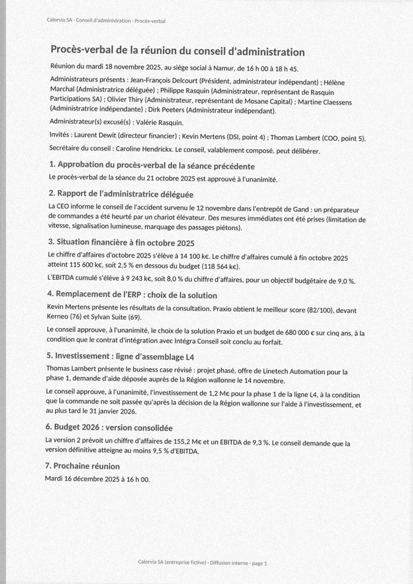

In [36]:
def page_image(path, page, dpi=150):
    """One page of a PDF as a PIL image."""
    with pymupdf.open(path) as pdf:
        pixmap = pdf[page].get_pixmap(dpi=dpi)
    return Image.open(io.BytesIO(pixmap.tobytes("png")))


scan = CORPUS / "00_Direction/Conseil_administration/PV_signes/PV CA 2025-11-18 signé.pdf"
first_page = page_image(scan, 0)
print(first_page.size)
first_page.resize((first_page.width // 3, first_page.height // 3))

Docling sait aussi faire de l'OCR sur les PDF (options `do_ocr` et `ocr_options` de `PdfPipelineOptions`, avec RapidOCR, EasyOCR ou Tesseract). Les modèles d'OCR doivent alors être téléchargés à l'avance, et les noms des options changent d'une version de Docling à l'autre : vérifiez dans la documentation de votre version. L'avantage du VLM : un seul outil pour les scans et les images, qui lit aussi l'écriture manuscrite (les annotations des bons de livraison) et décrit ce qui n'est pas du texte.

À comparer dans votre rapport, sur les questions `scan_ocr` : OCR de Docling ou VLM, qualité et temps.

### 3.7 Les images à l'intérieur d'un document

L'annexe de l'enquête télétravail et le rapport RSE contiennent des graphiques dont les valeurs ne sont pas dans le texte. PyMuPDF sait extraire les images d'un PDF ; on les transcrit avec la même fonction.

[(0, (1320, 715)), (0, (1320, 715))]


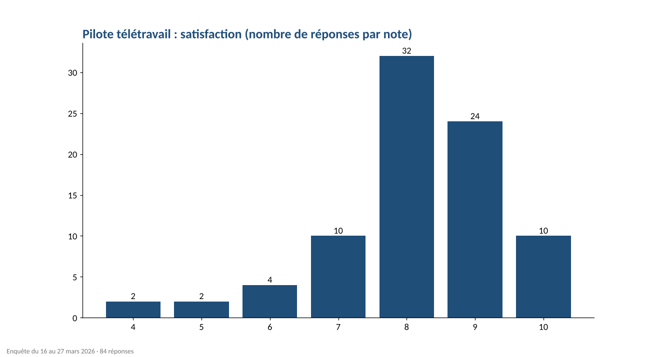

In [37]:
def pdf_images(path, min_side=200):
    """Images embedded in a PDF, larger than `min_side` pixels: [(page, PIL image)]."""
    found = []
    with pymupdf.open(path) as pdf:
        for page_number, page in enumerate(pdf):
            for xref, *_ in page.get_images():
                image = Image.open(io.BytesIO(pdf.extract_image(xref)["image"]))
                if min(image.size) >= min_side:
                    found.append((page_number, image))
    return found


annex = CORPUS / "00_Direction/CODIR/Annexes/2026-04-13 Annexe - Resultats enquete teletravail.pdf"
embedded = pdf_images(annex)
print([(page, image.size) for page, image in embedded])
embedded[1][1].resize((embedded[1][1].width // 2, embedded[1][1].height // 2))

Docling propose la même chose dans sa conversion : `do_picture_description=True` et `PictureDescriptionApiOptions`, qui envoient chaque image du document à un serveur compatible OpenAI (votre llama-server), avec votre prompt. La description est rangée dans le document Docling, à côté de l'image. Là encore, vérifiez les noms exacts dans la documentation de votre version.

### 3.8 Des chunks à partir des transcriptions

La transcription devient un ou plusieurs chunks. Deux points :

- **le texte du chunk commence par ce qu'est l'image** : son titre (tiré du nom du fichier), son dossier, sa date. Sans cela, « Achats : Céline Moreau » ne dit pas que c'est l'organigramme d'avril 2026 ;
- **le payload garde le chemin de l'image** (et la page pour un scan) : c'est ce qui permet de l'afficher dans le chat (section suivante) et de comparer avec la vérité terrain (`document` = chemin relatif du fichier).

In [38]:
def image_chunk(relative_path, transcription, page=None):
    """Text and payload of a chunk built from an image transcription."""
    path = Path(relative_path)
    header = f"Image : {path.stem} (dossier {path.parent})" + (f", page {page + 1}" if page is not None else "")
    payload = {"document": relative_path, "source_type": "scan" if page is not None else "image",
               "image_path": relative_path, "page": page}
    return {"text": f"{header}\n{transcription}", "payload": payload}

### 3.9 Bonus : afficher l'image dans le chat

Quand la réponse s'appuie sur une image, l'utilisateur veut la voir : il peut ainsi vérifier un nombre lu par le VLM. Après la recherche, on parcourt les payloads des chunks retenus ; pour chaque chunk qui vient d'une image ou d'une page scannée, on prépare l'image à afficher.

In [39]:
def source_images(payloads, max_images=3, max_side=900):
    """Images to show next to the answer: [(caption, JPEG bytes)], without duplicates."""
    seen, images = set(), []
    for payload in payloads:
        path, page = payload.get("image_path"), payload.get("page")
        if not path or (path, page) in seen:
            continue
        seen.add((path, page))
        image = page_image(CORPUS / path, page, dpi=100) if page is not None else Image.open(CORPUS / path)
        image.thumbnail((max_side, max_side))
        buffer = io.BytesIO()
        image.convert("RGB").save(buffer, format="JPEG", quality=85)
        caption = path + (f", page {page + 1}" if page is not None else "")
        images.append((caption, buffer.getvalue()))
        if len(images) == max_images:
            break
    return images

Exemple avec deux payloads écrits à la main, de la forme que Qdrant renverrait (`[point.payload for point in points]`) :

02_RH/Organigrammes/Organigramme direction 2026-04.png


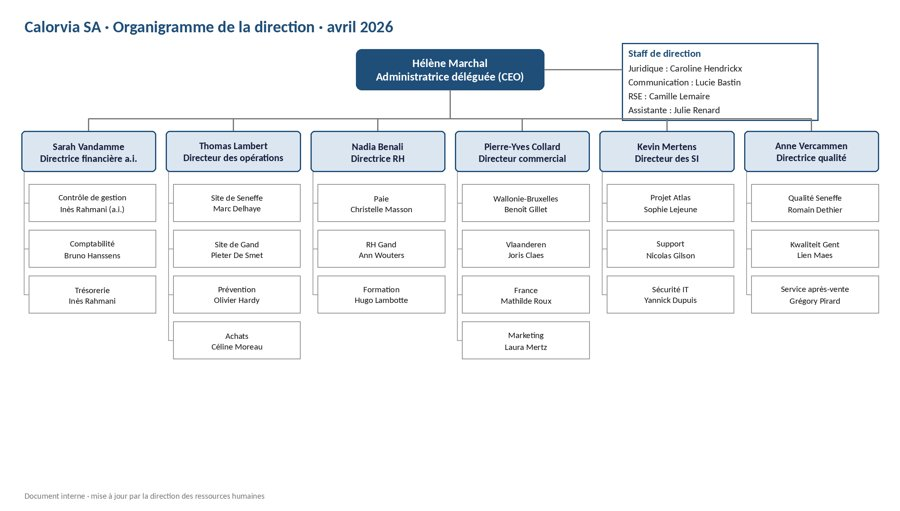

00_Direction/Conseil_administration/PV_signes/PV CA 2025-12-16 signé.pdf, page 1


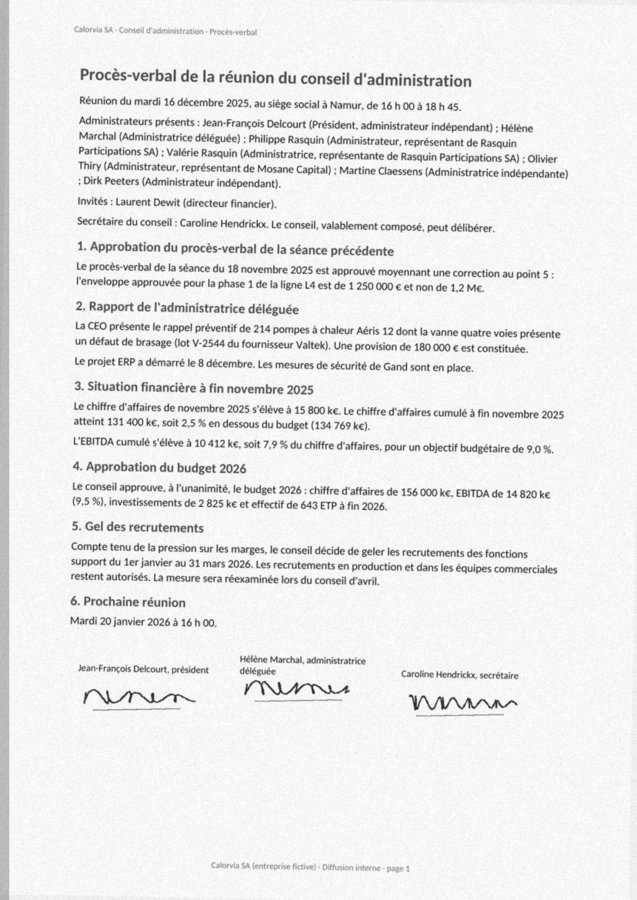

In [40]:
from IPython.display import Image as DisplayImage, display

payloads = [
    {"document": "02_RH/Organigrammes/Organigramme direction 2026-04.png",
     "image_path": "02_RH/Organigrammes/Organigramme direction 2026-04.png", "page": None},
    {"document": "00_Direction/Conseil_administration/PV_signes/PV CA 2025-12-16 signé.pdf",
     "image_path": "00_Direction/Conseil_administration/PV_signes/PV CA 2025-12-16 signé.pdf", "page": 0},
    {"document": "00_Direction/CODIR/2026/2026-04-13 CODIR PV.docx"},          # text chunk: no image
]
for caption, jpeg in source_images(payloads):
    print(caption)
    display(DisplayImage(data=jpeg, width=600))

Dans une interface Streamlit, la même liste s'affiche sous la réponse :

```python
import streamlit as st

st.markdown(answer)
for caption, jpeg in source_images([point.payload for point in points]):
    st.image(jpeg, caption=caption)
```

Deux améliorations :

- **n'afficher que les images citées** : avec le prompt `citations.txt` de l'exercice 3, la réponse cite les extraits utilisés ([2]) ; on n'affiche que les images de ces extraits ;
- **derrière une API** (FastAPI, plus tard), on ne renvoie pas l'image elle-même mais son adresse : une route qui sert les fichiers du corpus, et la réponse JSON contient la liste des images à afficher.

## À retenir

- La **langue** : détectez-la par chunk, gardez-la dans le payload pour le stemmer et l'analyse, jamais comme filtre. La recherche dense multilingue fait le pont entre les langues ; traduire la question aide la recherche lexicale.
- Les **Excel** : lisez-les avec openpyxl (`data_only=True`), retrouvez les tableaux, écrivez une phrase par ligne avec son contexte (fichier, onglet, titre, période). Pour additionner ou comparer, calculez dans le code plutôt que de demander au LLM.
- Les **images et les scans** : un VLM servi par llama-server transcrit et décrit ; gardez le résultat en cache, vérifiez les nombres, mettez le chemin de l'image dans le payload pour pouvoir l'afficher dans le chat.